# Análise Estatística do Tempo de Internamento (Length of Stay - LOS)
## Diabetes 130-US Hospitals Dataset

Este notebook realiza a **análise estatística descritiva e comparativa exclusivamente** para o tempo de internamento hospitalar (*Length of Stay* - `time_in_hospital`), avaliando a sua relação com as colunas categóricas clínicas especificadas:
- `age` (Faixa Etária)
- `gender` (Género)
- `diag_1` (Código de Diagnóstico Principal ICD-9-CM, agrupado por categoria clínica)
- `medical_specialty` (Serviço / Especialidade Médica)

In [3]:
# ==============================================================================
# 1. IMPORTAÇÃO DE BIBLIOTECAS E CONFIGURAÇÕES
# ==============================================================================
# !pip install -q kagglehub scipy seaborn matplotlib pandas numpy

import os
import warnings
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import csv
from scipy import stats
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 100

In [4]:
# ==============================================================================
# 2. CARREGAMENTO DO DATASET E FILTRAGEM DE COLUNAS
# ==============================================================================
print("Carregando o dataset Diabetes 130-US hospitals...")
path = kagglehub.dataset_download("brandao/diabetes")
csv_path = os.path.join(path, "diabetic_data.csv")

df_raw = pd.read_csv(csv_path)

# Seleção estrita das 5 variáveis de interesse
cols = ['age', 'gender', 'time_in_hospital', 'diag_1', 'medical_specialty']
df = df_raw[cols].copy()

print(f"Subset criado com sucesso: {df.shape[0]} registos x {df.shape[1]} colunas.")
df.head()

Carregando o dataset Diabetes 130-US hospitals...
Subset criado com sucesso: 101766 registos x 5 colunas.


,age,gender,time_in_hospital,diag_1,medical_specialty
0,[0-10),Female,1,250.83,Pediatrics-Endocrinology
1,[10-20),Female,3,276,?
2,[20-30),Female,2,648,?
3,[30-40),Male,2,8,?
4,[40-50),Male,1,197,?


In [5]:
# ==============================================================================
# 3. TRATAMENTO E MAPEAMENTO DE DIAGNÓSTICO PARA SERVIÇO MÉDICO
# ==============================================================================
# NOTA: no Diabetes 130-US Hospitals, diag_1 contém códigos ICD-9-CM.
# O mapeamento abaixo é uma INFERÊNCIA por intervalos/categorias de diagnóstico.
# Não representa necessariamente o serviço que tratou efetivamente o doente.

# 1. Limpeza dos códigos
df['diag_1'] = df['diag_1'].fillna('?').astype(str).str.strip()
df['diag_1'] = df['diag_1'].replace({'?': 'Desconhecido', 'nan': 'Desconhecido'})

# 2. Classificação do código ICD-9-CM em grandes grupos clínicos
def classificar_codigo_icd9(code):
    if pd.isna(code) or str(code).strip() in ('', '?', 'Desconhecido'):
        return 'Outro/Desconhecido'

    code_str = str(code).strip().upper()

    # Códigos suplementares ICD-9-CM
    if code_str.startswith('V'):
        return 'Fatores de Saúde (V00-V99)'
    if code_str.startswith('E'):
        return 'Causas Externas (E000-E999)'

    try:
        valor = float(code_str)
    except (ValueError, TypeError):
        return 'Outro/Desconhecido'

    codigo = int(np.floor(valor))

    if 1 <= codigo <= 139:
        return 'Infeciosas e Parasitárias'
    elif 140 <= codigo <= 239:
        return 'Neoplasias'
    elif 240 <= codigo <= 279:
        return 'Endócrinas, Nutricionais e Metabólicas'
    elif 280 <= codigo <= 289:
        return 'Sangue e Órgãos Hematopoiéticos'
    elif 290 <= codigo <= 319:
        return 'Perturbações Mentais'
    elif 320 <= codigo <= 389:
        return 'Sistema Nervoso e Órgãos dos Sentidos'
    elif 390 <= codigo <= 459:
        return 'Sistema Circulatório'
    elif 460 <= codigo <= 519:
        return 'Sistema Respiratório'
    elif 520 <= codigo <= 579:
        return 'Sistema Digestivo'
    elif 580 <= codigo <= 629:
        return 'Sistema Geniturinário'
    elif 630 <= codigo <= 679:
        return 'Gravidez, Parto e Puerpério'
    elif 680 <= codigo <= 709:
        return 'Pele e Tecido Subcutâneo'
    elif 710 <= codigo <= 739:
        return 'Sistema Osteomuscular'
    elif 740 <= codigo <= 759:
        return 'Anomalias Congénitas'
    elif 760 <= codigo <= 779:
        return 'Condições Perinatais'
    elif 780 <= codigo <= 799:
        return 'Sintomas e Sinais'
    elif 800 <= codigo <= 999:
        return 'Lesões e Intoxicações'
    else:
        return 'Outro/Desconhecido'

df['grupo_diagnostico'] = df['diag_1'].apply(classificar_codigo_icd9)

# 3. Dicionário que associa grupos de diagnóstico a serviços.
# São regras indicativas; alguns diagnósticos podem exigir outras especialidades.
mapeamento_servico_por_grupo = {
    'Infeciosas e Parasitárias': 'Infectologia',
    'Neoplasias': 'Oncologia',
    'Endócrinas, Nutricionais e Metabólicas': 'Endocrinologia',
    'Sangue e Órgãos Hematopoiéticos': 'Hematologia',
    'Perturbações Mentais': 'Psiquiatria',
    'Sistema Nervoso e Órgãos dos Sentidos': 'Neurologia',
    'Sistema Circulatório': 'Cardiologia',
    'Sistema Respiratório': 'Pneumologia',
    'Sistema Digestivo': 'Gastroenterologia',
    'Sistema Geniturinário': 'Urologia/Nefrologia',
    'Gravidez, Parto e Puerpério': 'Obstetrícia',
    'Pele e Tecido Subcutâneo': 'Dermatologia',
    'Sistema Osteomuscular': 'Ortopedia',
    'Anomalias Congénitas': 'Genética/Especialidade Pediátrica',
    'Condições Perinatais': 'Neonatologia',
    'Sintomas e Sinais': 'Medicina Interna',
    'Lesões e Intoxicações': 'Cirurgia Geral/Traumatologia',
    'Fatores de Saúde (V00-V99)': 'Medicina Preventiva/Outros',
    'Causas Externas (E000-E999)': 'Urgência/Traumatologia'
}

# 4. Serviço inferido diretamente a partir do código de diagnóstico
df['servico_por_codigo'] = df['grupo_diagnostico'].map(
    mapeamento_servico_por_grupo
).fillna('Não Especificado')

# 5. Preservar a especialidade original e normalizar algumas categorias registadas
df['medical_specialty_original'] = df['medical_specialty'].copy()
padronizar_especialidade = {
    'InternalMedicine': 'Medicina Interna',
    'Cardiology': 'Cardiologia',
    'Emergency/Trauma': 'Emergência/Trauma',
    'Family/GeneralPractice': 'Clínica Geral/Familiar',
    'Surgery-General': 'Cirurgia Geral'
}
df['medical_specialty'] = df['medical_specialty'].replace(padronizar_especialidade)

# 6. Serviço final: dá prioridade à especialidade registada.
# Só utiliza o serviço inferido pelo código quando a especialidade está ausente.
def atribuir_servico(row):
    especialidade = row['medical_specialty']
    if pd.notna(especialidade) and str(especialidade).strip() not in ('', '?', 'Unknown'):
        return especialidade

    servico_codigo = row['servico_por_codigo']
    if pd.notna(servico_codigo) and servico_codigo != 'Não Especificado':
        return servico_codigo

    return 'Não Especificado'

df['servico_medico_inferido'] = df.apply(atribuir_servico, axis=1)

# IMPORTANTE: atualizar a coluna principal para que medical_specialty já não
# apresente '?' quando o diagnóstico permite inferir um serviço.
# A informação original continua preservada em medical_specialty_original.
df['medical_specialty'] = df['servico_medico_inferido']

# 7. Agrupamento opcional: manter as 8 categorias mais frequentes para os gráficos.
top_especialidades = df['servico_medico_inferido'].value_counts().head(8).index
df['servico_medico'] = df['servico_medico_inferido'].apply(
    lambda x: x if x in top_especialidades else 'Outros Serviços'
)

print('Mapeamento código ICD-9-CM -> grupo diagnóstico -> serviço concluído.')
print('Colunas criadas: grupo_diagnostico, servico_por_codigo, '
      'servico_medico_inferido e servico_medico.')
print('Atenção: o serviço inferido é uma estimativa baseada no diagnóstico.')


Mapeamento código ICD-9-CM -> grupo diagnóstico -> serviço concluído.
Colunas criadas: grupo_diagnostico, servico_por_codigo, servico_medico_inferido e servico_medico.
Atenção: o serviço inferido é uma estimativa baseada no diagnóstico.


In [6]:
# ==============================================================================
# 4. ANÁLISE ESTATÍSTICA DESCRITIVA DO LENGTH OF STAY (LOS)
# ==============================================================================
print("=== ESTATÍSTICA GERAL DE TEMPO DE INTERNAMENTO (DIAS) ===")
stats_los = df[['time_in_hospital']].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats_los.columns = ['Média', 'Desv. Padrão', 'Mínimo', 'Q1 (25%)', 'Mediana (50%)', 'Q3 (75%)', 'Máximo']
display(stats_los)

print("\n=== MÉDIA E MEDIANA DE INTERNAMENTO POR SERVIÇO / ESPECIALIDADE ===")
los_servico = df.groupby('servico_medico')['time_in_hospital'].agg(['count', 'mean', 'median', 'std']).rename(
    columns={'count': 'Total Pacientes', 'mean': 'Média (Dias)', 'median': 'Mediana (Dias)', 'std': 'Desv. Padrão'}
).sort_values(by='Média (Dias)', ascending=False)
display(los_servico)

print("\n=== MÉDIA E MEDIANA DE INTERNAMENTO POR GRUPO DE DIAGNÓSTICO ICD-9-CM ===")
los_icd = df.groupby('grupo_diagnostico')['time_in_hospital'].agg(['count', 'mean', 'median', 'std']).rename(
    columns={'count': 'Total Pacientes', 'mean': 'Média (Dias)', 'median': 'Mediana (Dias)', 'std': 'Desv. Padrão'}
).sort_values(by='Média (Dias)', ascending=False)
display(los_icd)

=== ESTATÍSTICA GERAL DE TEMPO DE INTERNAMENTO (DIAS) ===


,Média,Desv. Padrão,Mínimo,Q1 (25%),Mediana (50%),Q3 (75%),Máximo
time_in_hospital,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0



=== MÉDIA E MEDIANA DE INTERNAMENTO POR SERVIÇO / ESPECIALIDADE ===


,Total Pacientes,Média (Dias),Mediana (Dias),Desv. Padrão
servico_medico,,,,
Pneumologia,5717,4.835228,4.0,2.896415
Outros Serviços,28779,4.652629,4.0,3.103180
Cirurgia Geral/Traumatologia,3452,4.619641,4.0,2.947015
Gastroenterologia,4806,4.406575,4.0,2.814913
Clínica Geral/Familiar,7440,4.363441,4.0,2.949484
Emergência/Trauma,7565,4.359683,4.0,2.833851
Endocrinologia,5572,4.252872,3.0,2.937655
Medicina Interna,18380,4.214527,3.0,2.974849
Cardiologia,20055,4.093293,3.0,2.926585



=== MÉDIA E MEDIANA DE INTERNAMENTO POR GRUPO DE DIAGNÓSTICO ICD-9-CM ===


,Total Pacientes,Média (Dias),Mediana (Dias),Desv. Padrão
grupo_diagnostico,,,,
Fatores de Saúde (V00-V99),1644,7.518248,7.0,3.705735
Perturbações Mentais,2262,5.860301,5.0,3.560053
Infeciosas e Parasitárias,2768,5.361272,5.0,3.200827
Neoplasias,3433,5.356248,5.0,3.351030
Sistema Respiratório,10407,5.041991,4.0,2.972270
Causas Externas (E000-E999),1,5.000000,5.0,NaN
Pele e Tecido Subcutâneo,2530,4.901581,4.0,2.881232
Anomalias Congénitas,51,4.843137,5.0,2.866165
Lesões e Intoxicações,6974,4.616432,4.0,2.953654


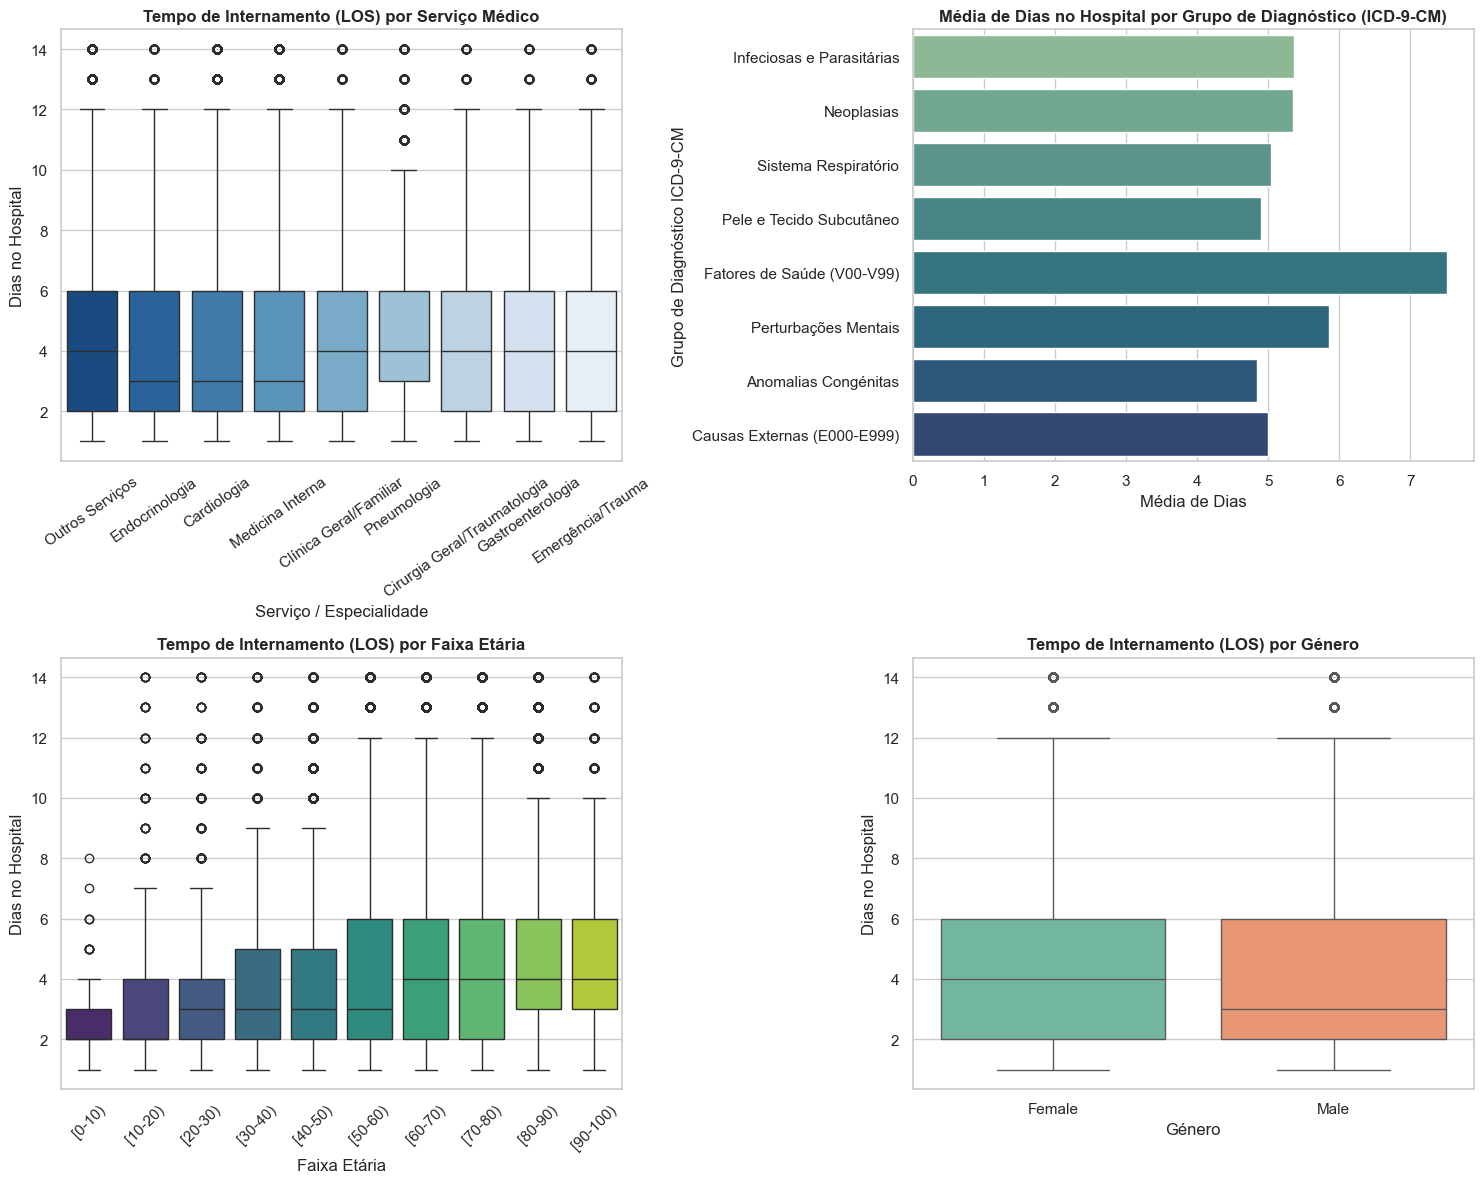

In [7]:
# ==============================================================================
# 5. VISUALIZAÇÕES GRÁFICAS (DISTRIBUIÇÃO E BOXPLOTS DE INTERNAMENTO)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 5.1. Tempo de Internamento por Serviço Médico (Boxplot)
sns.boxplot(data=df[df['servico_medico'] != 'Não Especificado'], x='servico_medico', y='time_in_hospital', ax=axes[0,0], palette='Blues_r')
axes[0,0].set_title('Tempo de Internamento (LOS) por Serviço Médico', fontweight='bold')
axes[0,0].set_xlabel('Serviço / Especialidade')
axes[0,0].set_ylabel('Dias no Hospital')
axes[0,0].tick_params(axis='x', rotation=35)

# 5.2. Tempo de Internamento por Grupo de Diagnóstico ICD-9-CM (Barplot)
top_icd_order = los_icd.head(8).index
sns.barplot(data=df[df['grupo_diagnostico'].isin(top_icd_order)], y='grupo_diagnostico', x='time_in_hospital', ax=axes[0,1], palette='crest', ci=None)
axes[0,1].set_title('Média de Dias no Hospital por Grupo de Diagnóstico (ICD-9-CM)', fontweight='bold')
axes[0,1].set_xlabel('Média de Dias')
axes[0,1].set_ylabel('Grupo de Diagnóstico ICD-9-CM')

# 5.3. Tempo de Internamento por Faixa Etária (age)
sns.boxplot(data=df, x='age', y='time_in_hospital', ax=axes[1,0], palette='viridis')
axes[1,0].set_title('Tempo de Internamento (LOS) por Faixa Etária', fontweight='bold')
axes[1,0].set_xlabel('Faixa Etária')
axes[1,0].set_ylabel('Dias no Hospital')
axes[1,0].tick_params(axis='x', rotation=45)

# 5.4. Tempo de Internamento por Género (gender)
sns.boxplot(data=df[df['gender'] != 'Unknown/Invalid'], x='gender', y='time_in_hospital', ax=axes[1,1], palette='Set2')
axes[1,1].set_title('Tempo de Internamento (LOS) por Género', fontweight='bold')
axes[1,1].set_xlabel('Género')
axes[1,1].set_ylabel('Dias no Hospital')

plt.tight_layout()
plt.show()

In [8]:
# ==============================================================================
# 6. TESTES ESTATÍSTICOS DE HIPÓTESE (KRUSKAL-WALLIS)
# ==============================================================================
print("=== TESTES ESTATÍSTICOS NÃO-PARAMÉTRICOS (KRUSKAL-WALLIS) ===\n")

# Teste 1: LOS vs Serviço Médico
df_serv = df[df['servico_medico'] != 'Não Especificado']
g_serv = [group['time_in_hospital'].values for name, group in df_serv.groupby('servico_medico')]
h_serv, p_serv = stats.kruskal(*g_serv)
print(f"1. Serviço Médico vs LOS:")
print(f"   - Estatística H: {h_serv:.2f} | p-value: {p_serv:.4e}")
print(f"   - Resultado: {'Significativo (p < 0.05)' if p_serv < 0.05 else 'Não Significativo'}\n")

# Teste 2: LOS vs Grupo de Diagnóstico ICD-9-CM
g_icd = [group['time_in_hospital'].values for name, group in df.groupby('grupo_diagnostico')]
h_icd, p_icd = stats.kruskal(*g_icd)
print(f"2. Grupo de Diagnóstico ICD-9-CM vs LOS:")
print(f"   - Estatística H: {h_icd:.2f} | p-value: {p_icd:.4e}")
print(f"   - Resultado: {'Significativo (p < 0.05)' if p_icd < 0.05 else 'Não Significativo'}\n")

# Teste 3: LOS vs Faixa Etária
g_age = [group['time_in_hospital'].values for name, group in df.groupby('age')]
h_age, p_age = stats.kruskal(*g_age)
print(f"3. Faixa Etária vs LOS:")
print(f"   - Estatística H: {h_age:.2f} | p-value: {p_age:.4e}")
print(f"   - Resultado: {'Significativo (p < 0.05)' if p_age < 0.05 else 'Não Significativo'}")

=== TESTES ESTATÍSTICOS NÃO-PARAMÉTRICOS (KRUSKAL-WALLIS) ===

1. Serviço Médico vs LOS:
   - Estatística H: 896.63 | p-value: 3.0044e-188
   - Resultado: Significativo (p < 0.05)

2. Grupo de Diagnóstico ICD-9-CM vs LOS:
   - Estatística H: 6615.48 | p-value: 0.0000e+00
   - Resultado: Significativo (p < 0.05)

3. Faixa Etária vs LOS:
   - Estatística H: 1582.72 | p-value: 0.0000e+00
   - Resultado: Significativo (p < 0.05)


In [9]:
import pandas as pd

# 1. Preparar o subset final com a seleção e renomeação exata das colunas
df_csv = df[['gender', 'diag_1', 'age', 'time_in_hospital', 'servico_medico_inferido']].copy()
df_csv.columns = ['gender', 'diagnosis_code', 'age', 'los_days', 'service']

# 2. Guardar diretamente num ficheiro .csv
df_csv.to_csv('dados_pacientes.csv', index=False)

In [10]:
# ==============================================================================
# 9. VERIFICAÇÃO DO MAPEAMENTO FINAL DE SERVIÇOS
# ==============================================================================
print('=== ESPECIALIDADE ORIGINAL (ANTES DO MAPEAMENTO) ===')
print(df['medical_specialty_original'].value_counts(dropna=False).head(15))

print('\n=== MEDICAL_SPECIALTY FINAL (APÓS MAPEAMENTO) ===')
print(df['medical_specialty'].value_counts(dropna=False))

print('\n=== SERVIÇO FINAL INFERIDO ===')
print(df['servico_medico_inferido'].value_counts(dropna=False))

print('\n=== QUALIDADE DO MAPEAMENTO ===')
total = len(df)
sem_servico = df['servico_medico_inferido'].eq('Não Especificado').sum()
mapeados = total - sem_servico
print(f'Total de registos: {total:,}')
print(f'Registos com serviço atribuído: {mapeados:,} ({mapeados/total:.1%})')
print(f'Registos sem serviço identificável: {sem_servico:,} ({sem_servico/total:.1%})')

print('\n=== EXEMPLOS DE REGISTOS ANTES MARCADOS COM ? ===')
exemplos_mapeados = df.loc[
    df['medical_specialty_original'].astype(str).str.strip().eq('?'),
    ['medical_specialty_original', 'diag_1', 'grupo_diagnostico', 'servico_por_codigo', 'medical_specialty']
].head(10)
display(exemplos_mapeados)


=== ESPECIALIDADE ORIGINAL (ANTES DO MAPEAMENTO) ===
medical_specialty_original
?                                  49949
InternalMedicine                   14635
Emergency/Trauma                    7565
Family/GeneralPractice              7440
Cardiology                          5352
Surgery-General                     3099
Nephrology                          1613
Orthopedics                         1400
Orthopedics-Reconstructive          1233
Radiologist                         1140
Pulmonology                          871
Psychiatry                           854
Urology                              685
ObstetricsandGynecology              671
Surgery-Cardiovascular/Thoracic      652
Name: count, dtype: int64

=== MEDICAL_SPECIALTY FINAL (APÓS MAPEAMENTO) ===
medical_specialty
Cardiologia                         20055
Medicina Interna                    18380
Emergência/Trauma                    7565
Clínica Geral/Familiar               7440
Pneumologia                          5717


,medical_specialty_original,diag_1,grupo_diagnostico,servico_por_codigo,medical_specialty
1,?,276,"Endócrinas, Nutricionais e Metabólicas",Endocrinologia,Endocrinologia
2,?,648,"Gravidez, Parto e Puerpério",Obstetrícia,Obstetrícia
3,?,8,Infeciosas e Parasitárias,Infectologia,Infectologia
4,?,197,Neoplasias,Oncologia,Oncologia
5,?,414,Sistema Circulatório,Cardiologia,Cardiologia
6,?,414,Sistema Circulatório,Cardiologia,Cardiologia
7,?,428,Sistema Circulatório,Cardiologia,Cardiologia
8,?,398,Sistema Circulatório,Cardiologia,Cardiologia
10,?,250.7,"Endócrinas, Nutricionais e Metabólicas",Endocrinologia,Endocrinologia
11,?,157,Neoplasias,Oncologia,Oncologia


In [11]:
COLUNAS_FINAIS = ['gender', 'diagnosis_code', 'age', 'los_days', 'medical_specialty']

# Valores que o processo anterior deixou como texto em vez de nulos
VALORES_NULOS = ['?', 'nan', '', 'Desconhecido', 'Não Especificado', 'Unknown/Invalid']

df_csv = pd.DataFrame({
    'gender': df['gender'],
    'diagnosis_code': df['diag_1'],
    'age': df['age'],
    'los_days': df['time_in_hospital'],
    'medical_specialty': df['servico_medico_inferido'],
})

# 1. Converter placeholders e NaN reais em nulos
df_csv = df_csv.replace(VALORES_NULOS, np.nan)

# 2. Relatório dos nulos antes de remover
print("Nulos por coluna (antes da remoção):")
print(df_csv.isna().sum())

# 3. Remover linhas com qualquer nulo
antes = len(df_csv)
df_csv = df_csv.dropna().reset_index(drop=True)
print(f"\nRegistos removidos: {antes - len(df_csv):,} ({(antes - len(df_csv)) / antes:.2%})")

# 4. Garantir colunas e ordem exatas
df_csv = df_csv[COLUNAS_FINAIS]
assert list(df_csv.columns) == COLUNAS_FINAIS
assert df_csv.isna().sum().sum() == 0

# 5. Guardar
df_csv.to_csv('dados_pacientes.csv', index=False)
print(f"CSV guardado: {df_csv.shape[0]:,} registos x {df_csv.shape[1]} colunas")
print(df_csv.head())

Nulos por coluna (antes da remoção):
gender                3
diagnosis_code       21
age                   0
los_days              0
medical_specialty     8
dtype: int64

Registos removidos: 24 (0.02%)
CSV guardado: 101,742 registos x 5 colunas
   gender diagnosis_code      age  los_days         medical_specialty
0  Female         250.83   [0-10)         1  Pediatrics-Endocrinology
1  Female            276  [10-20)         3            Endocrinologia
2  Female            648  [20-30)         2               Obstetrícia
3    Male              8  [30-40)         2              Infectologia
4    Male            197  [40-50)         1                 Oncologia
